<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/03_pytorch_computer_vision_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. PyTorch Computer Vision Exercises

The following is a collection of exercises based on computer vision fundamentals in PyTorch.

They're a bunch of fun.

You're going to get to write plenty of code!

## Resources

1. These exercises are based on [notebook 03 of the Learn PyTorch for Deep Learning course](https://www.learnpytorch.io/03_pytorch_computer_vision/). 
2. See a live [walkthrough of the solutions (errors and all) on YouTube](https://youtu.be/_PibmqpEyhA). 
  * **Note:** Going through these exercises took me just over 3 hours of solid coding, so you should expect around the same.
3. See [other solutions on the course GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions).

In [1]:
# Check for GPU
!nvidia-smi

Thu Nov 26 20:40:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.57.01              KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce GTX 1660 ...    On  |   00000000:01:00.0  On |                  N/A |
| 30%   55C    P0             27W /  125W |     621MiB /   6144MiB |      2%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Import torch
import torch

# Exercises require PyTorch > 1.10.0
print(torch.__version__)

device = "cuda" if torch.cuda.is_available() else "cpu"
device

2.15.0+cu132


'cuda'

## 1. What are 3 areas in industry where computer vision is currently being used?

In [3]:
# Reconhecimento de faces, análise de exames médicos e extração de informações de documentos

## 2. Search "what is overfitting in machine learning" and write down a sentence about what you find. 

In [4]:
# Overfitting acontece quando um modelo aprende os ruídos dos dados em vez de aprender realmente os dados, nesse caso, quando testado em um dataset que não é o de treinamento
# ele vai performar mal, já que apenas reconhece os ruídos dos dados de treinamente e não capturou nenhum padrão nos dados

## 3. Search "ways to prevent overfitting in machine learning", write down 3 of the things you find and a sentence about each. 
> **Note:** there are lots of these, so don't worry too much about all of them, just pick 3 and start with those.

In [5]:
# Maneira 1 -> Aumentar a quantidade de dados -> aumenta a variância dos ruídos e a diversidade de padrões
# Maneira 2 -> Usar conjuntos de validação cruzada -> Varia os dados do treinamento, evitando capturar padrões indesejados
# Maneira 3 -> Simplificar o modelo -> As vezes o modelo está aprendendo padrões complexos demais, e não está capturando o básico

## 4. Spend 20-minutes reading and clicking through the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/).

* Upload your own example image using the "upload" button on the website and see what happens in each layer of a CNN as your image passes through it.

In [6]:
#...

## 5. Load the [`torchvision.datasets.MNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST) train and test datasets.

In [41]:
from torchvision.datasets.mnist import MNIST
from torchvision.transforms import ToTensor

train = MNIST("/home/pedro/pytorch-deep-learning/data/FashionMNIST/raw", train=True, download=True, transform=ToTensor())
test = MNIST("/home/pedro/pytorch-deep-learning/data/FashionMNIST/raw", train=False, download=True, transform=ToTensor())

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.90MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 280kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.67MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.4MB/s]


## 6. Visualize at least 5 different samples of the MNIST training dataset.

torch.Size([1, 28, 28])
torch.Size([1, 28, 28])
torch.Size([1, 28, 28])
torch.Size([1, 28, 28])
torch.Size([1, 28, 28])


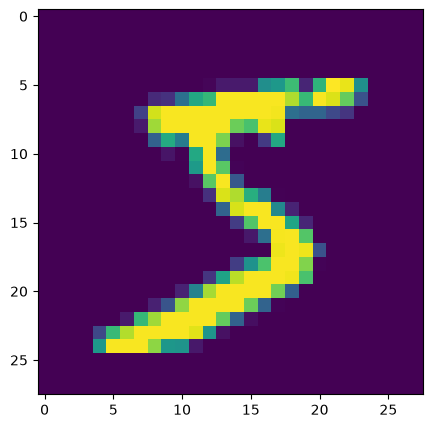

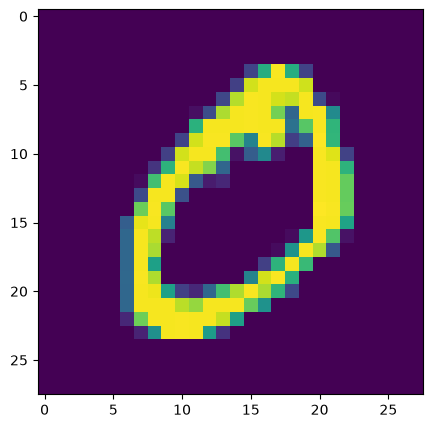

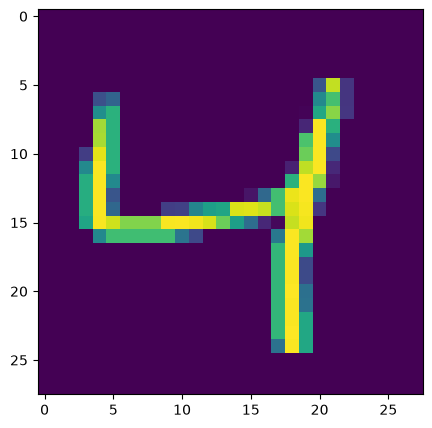

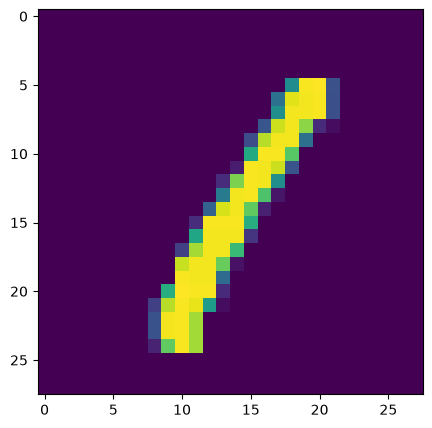

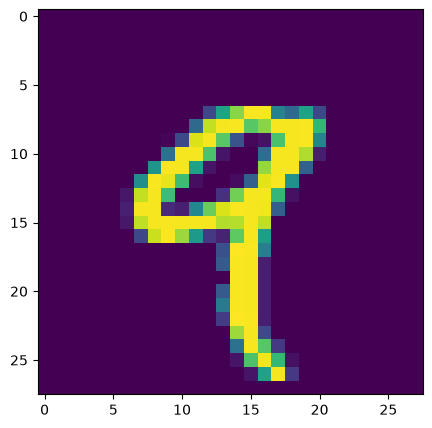

In [52]:
import matplotlib.pyplot as plt
for idx in range(5):
    plt.figure(figsize=(5, 5))
    image, label = train[idx]
    plt.imshow(image.squeeze())
    print(image.shape)


## 7. Turn the MNIST train and test datasets into dataloaders using `torch.utils.data.DataLoader`, set the `batch_size=32`.

In [43]:
from torch.utils.data.dataloader import DataLoader

train_dl = DataLoader(train, batch_size=32, shuffle=True)
test_dl = DataLoader(test, batch_size=32, shuffle=True)

## 8. Recreate `model_2` used in notebook 03 (the same model from the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/), also known as TinyVGG) capable of fitting on the MNIST dataset.

In [65]:
import torch.nn as nn

class Model(nn.Module):
    def __init__(self, input_chan, hidden, output):
        super().__init__()
        self.layer_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_chan, out_channels=hidden, kernel_size=3, stride=1, padding=1),
            nn.ReLU()
        )
        self.layer_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer_3 = nn.Sequential(
            nn.Conv2d(in_channels=hidden, out_channels=hidden, kernel_size=3, padding=1),
            nn.ReLU(),
        )
        self.layer_4 = nn.Sequential(
            nn.Conv2d(in_channels=hidden, out_channels=hidden, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer_5 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden * 7 * 7, out_features=output)
        )

    def forward(self, x):
        x = self.layer_1(x)
        x = self.layer_2(x)
        x = self.layer_3(x)
        x = self.layer_4(x)
        x = self.layer_5(x)
        return x        

In [66]:
model = Model(input_chan=1, hidden=10, output=len(train.classes))

## 9. Train the model you built in exercise 8. for 5 epochs on CPU and GPU and see how long it takes on each.

In [46]:
import sys
from pathlib import Path

parent_dir = str(Path.cwd().parent.parent)
if parent_dir not in sys.path:
  sys.path.insert(0, parent_dir)

from helper_functions import accuracy_fn

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [74]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.1)

In [ ]:
EPOCHS = 5


model.to(device)
for epoch in range(EPOCHS):
    train_loss, test_loss = 0, 0
    train_acc,  test_acc = 0, 0
    for X, y in train_dl:
        model.train()
        X, y = X.to(device), y.to(device)

        y_pred = model(X)

        loss = loss_fn(y_pred, y)
        
        train_loss += loss

        acc = accuracy_fn(y, y_pred.argmax(dim=1))
        train_acc += acc

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

    train_loss /= len(train_dl)
    train_acc /= len(train_dl)

    print(f"Train loss: {train_loss:.2f}, Train acc: {train_acc:.2f}")

    with torch.inference_mode():
        model.eval()
        for X, y in test_dl:
            X, y = X.to(device), y.to(device)

            test_pred = model(X)

            loss = loss_fn(test_pred, y)
            test_loss += loss

            acc = accuracy_fn(y, test_pred.argmax(dim=1))
            test_acc += acc

        test_loss /= len(test_dl)
        test_acc /= len(test_dl)

        print(f"Test loss: {test_loss:.2f}, Test acc: {test_acc:.2f}")


Train loss: 0.02, Train acc: 99.25
Test loss: 0.04, Test acc: 98.87
Train loss: 0.02, Train acc: 99.33
Test loss: 0.03, Test acc: 98.92
Train loss: 0.02, Train acc: 99.34
Test loss: 0.04, Test acc: 98.89


## 10. Make predictions using your trained model and visualize at least 5 of them comparing the prediciton to the target label.

## 11. Plot a confusion matrix comparing your model's predictions to the truth labels.

## 12. Create a random tensor of shape `[1, 3, 64, 64]` and pass it through a `nn.Conv2d()` layer with various hyperparameter settings (these can be any settings you choose), what do you notice if the `kernel_size` parameter goes up and down?

## 13. Use a model similar to the trained `model_2` from notebook 03 to make predictions on the test [`torchvision.datasets.FashionMNIST`](https://pytorch.org/vision/main/generated/torchvision.datasets.FashionMNIST.html) dataset. 
* Then plot some predictions where the model was wrong alongside what the label of the image should've been. 
* After visualing these predictions do you think it's more of a modelling error or a data error? 
* As in, could the model do better or are the labels of the data too close to each other (e.g. a "Shirt" label is too close to "T-shirt/top")?